## Homework 3 - Analysis Using the $p$, $np$, $c$, and $u$ Control Charts
### Dr. Austin Brown
### Kennesaw State University

**DUE: October 30, 2026 via D2L**

## Instructions:

Ravi's Comics and Games is a local comic book and tabletop game shop that receives weekly new-release shipments from a regional distributor. Ravi's customers, especially the collectors chasing near-mint copies, have started complaining more often about comics arriving with scratched or folded covers, and Ravi has noticed it's starting to hurt sales of his higher-end back issues too. He's asked your quality control team to help him figure out how bad the problem really is, whether it's getting better or worse, and who -- the distributor, or his own shop -- is responsible.

Your team decides to look at this two different ways. First, every comic in a week's shipment gets a quick pass/fail condition check as staff unbox and shelve it (any visible scratch, crease, or fold on the cover marks it nonconforming). Because the number of comics in a shipment varies week to week depending on the new-release schedule, your team tracks both the **rate** of nonconforming comics (useful for spotting trends) and the **raw count** (useful when Ravi calls the distributor's account representative, who thinks in terms of "how many books," not percentages).

Second, your team recognizes that a single comic can have more than one distinct defect on it -- a scratch on the front cover **and** a folded corner on the back, for example -- so a simple pass/fail check doesn't capture the full severity of the damage. To get a fuller picture, staff also perform a more detailed defect count each week, counting every individual scratch, fold, or dent they find (not just how many comics have at least one). This detailed count is done on two separate parts of the shop: a **fixed** sample of 5 boxes pulled from the new-release shipment every week, and a **variable** number of already-shelved back-issue boxes, inspected whenever staff have the time.

## Key Specifications

| Quantity | Value |
|---|---|
| Nonconforming definition (Datasets A) | Any visible scratch, crease, or fold on the cover |
| Nonconformity definition (Datasets B & C) | Each individual scratch, fold, or dent found (a comic may have more than one) |
| Dataset A: Shipment Condition, Phase I weeks (m) | 25 weeks, variable shipment size |
| Dataset A: Shipment Condition, Phase II weeks (m) | 20 weeks, variable shipment size |
| Dataset B: New-Release Defect Counts, weeks (m) | 25 weeks, fixed sample of 5 boxes/week |
| Dataset C: Back-Issue Defect Counts, weeks (m) | 25 weeks, variable number of boxes/week |

In [4]:
## Clone your forked repository to Colab ##

## Specify your GitHub username:
user_name <- "wasifmostofa36"

## Specify the repository:
repo_name <- "STAT-7110-Quality-Control"

## Set the web address to your forked repository:
repo_address <- paste0(
  "https://github.com/",
  user_name,
  "/",
  repo_name,
  ".git"
)

## Check to see if repo is already cloned to Colab, and if not, clone repo:
if (!dir.exists(repo_name)) {
  system(paste("git clone", repo_address))
} else {
  print("Repository already cloned to Colab.")
}
## Set working drive to today's lecture:

setwd("STAT-7110-Quality-Control//Assignments//HW3")

## Define & Measure

### Q1: Briefly describe the purpose of this analysis

The purpose of this analysis is to assess the condition of the comics Ravi receives in its weekly distributor shipments, and to determine whether the damage customers are complaining about is stable, improving, or worsening over time. We also would like to know if the damage is coming from his staff or from the distributor. We will do this by monitoring the average number of nonconformities per batch or sample of size of comic books that Ravi receives from his distributor.

### Q2: Ravi's team is monitoring two distinct quality characteristics here: a pass/fail condition check, and a detailed defect count. For each, classify the type of attribute data being collected, and briefly explain how this differs from the continuous, normally-distributed data used in your previous two homeworks.

 Processes where the quality characteristic that are inherently numeric use the Shewhart charts, or CUSUM/EWMA charts. However for non-continous analysis the following kinds of charts would be more applicable: np, C, or U chart. The np
 chart is a good fit when "nonconforming" is a fair pass/fail label. If we care about care about the number of nonconformities per unit, not just whether a unit passes or fails, a C chart would be apporpriate. Monitoring the average number of nonconformities per batch or sample of size 'N', a U chart would be best.

### Q3: For the pass/fail data (Dataset A), what practical factor determines whether you should build a $p$ chart or an $np$ chart? For the detailed defect-count data (Datasets B and C), what practical factor determines whether you should build a $c$ chart or a $u$ chart?

For Dataset A, since the Raw count would be the most important metric when talking with the distributor, a NP chart would be best. This will help us determine the 'count of how many units fail to conform'. The practical factor would be whether we want the actual count or the proporation of pass/fail in the shipment.

For the detailed defect count data, a U chart would be best here. We are wanting to monitor the average number of nonconformities per batch or sample of size of comic books.The practical facor would be wanting understand either the average number of nonconformaties per batch OR the number of nonconformaties per unit.

## Analyze

### Q4: Read the Phase I Shipment Condition data (Dataset A) into R. Construct a Phase I $p$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Package 'qcc' version 2.7

Type 'citation("qcc")' for citing this R package in publications.



Week,TotalComics,NumberNonconforming
<dbl>,<dbl>,<dbl>
1,194,7
2,216,8
3,149,6
4,142,8
5,124,5
6,212,17


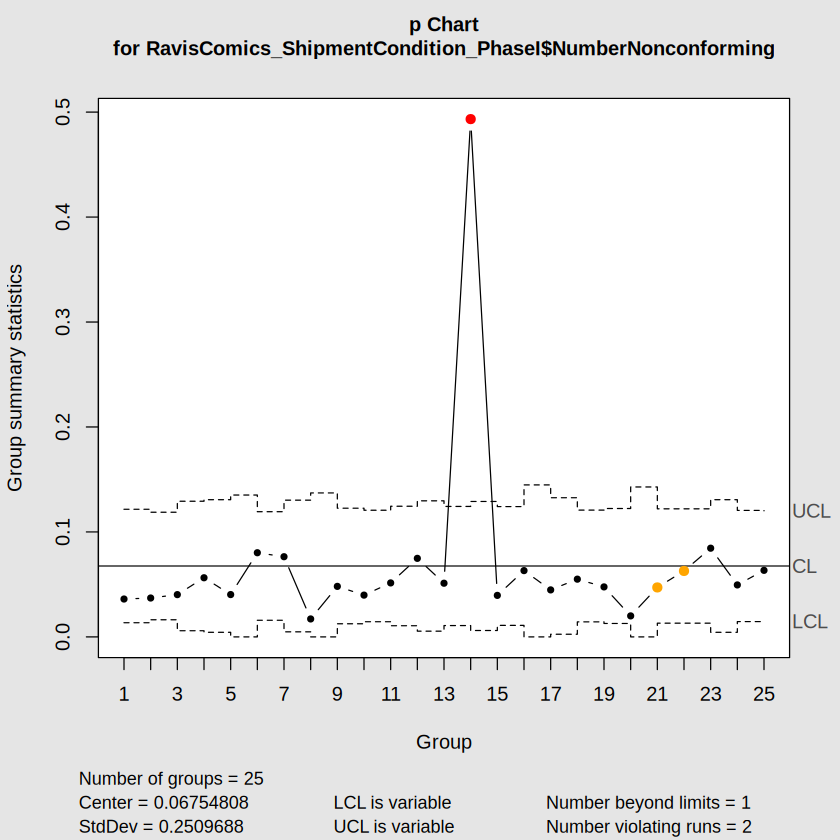

In [5]:
## Q4 Code ##

## Load the Libraries ##
install.packages("tidyverse")
install.packages("readxl")
install.packages("qcc")
library(tidyverse)
library(readxl)
library(qcc)

RavisComics_ShipmentCondition_PhaseI <- read_xlsx("RavisComics_ShipmentCondition_PhaseI.xlsx")
RavisComics_ShipmentCondition_PhaseI |>
  head()

RavisComics_chart <- qcc(RavisComics_ShipmentCondition_PhaseI$'NumberNonconforming',
                         type="p",
                         sizes=RavisComics_ShipmentCondition_PhaseI$'TotalComics',
                         plot=TRUE)

The chart does not show statistical control. There are 2 violating runs. Week 14 is beyond the upper limit. One possible explanation for this is that there may have been some damage to the comics during the journey from the distributor to the Ravi's store.Will omit group 14 and re-run phase 1.

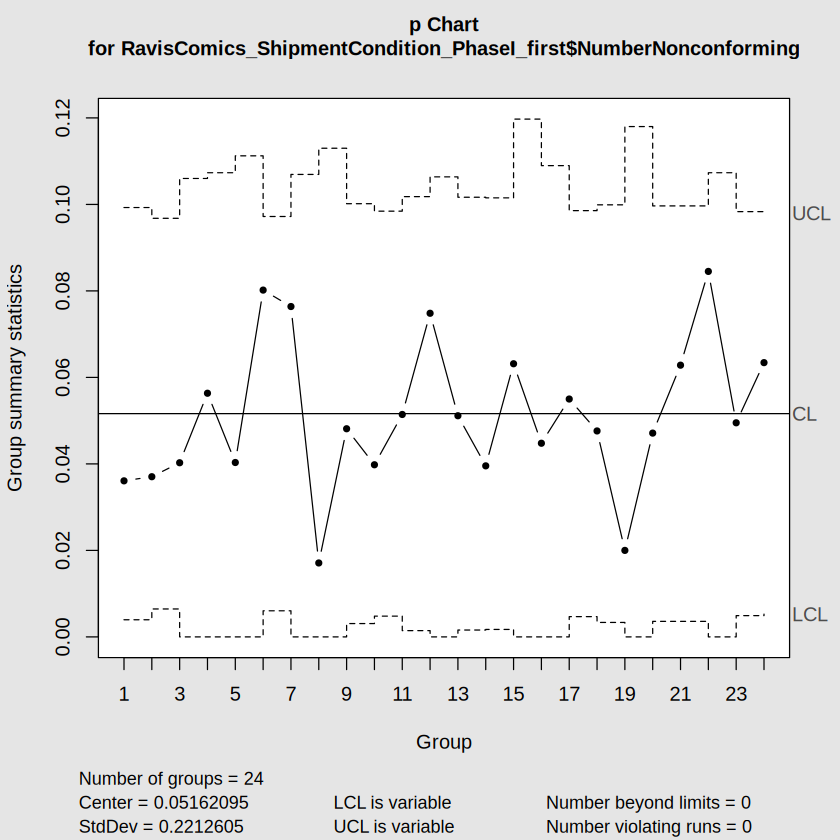

In [6]:
## Omitting OOC Points ##

ooc_points <- RavisComics_chart$violations$beyond.limits

RavisComics_ShipmentCondition_PhaseI_first <- RavisComics_ShipmentCondition_PhaseI[-ooc_points,]

RavisComics_ShipmentCondition_PhaseI_firstchart <- qcc(RavisComics_ShipmentCondition_PhaseI_first$NumberNonconforming,
                       type="p",
                       sizes=RavisComics_ShipmentCondition_PhaseI_first$TotalComics,
                       plot=TRUE)

#statistical control is reached

### Q5: Repeat the analysis in Q4, this time constructing an $np$ chart on the same data. Do your conclusions about which week(s) are out of control change? Which chart do you think would be easier to explain to the distributor's account representative, and why?

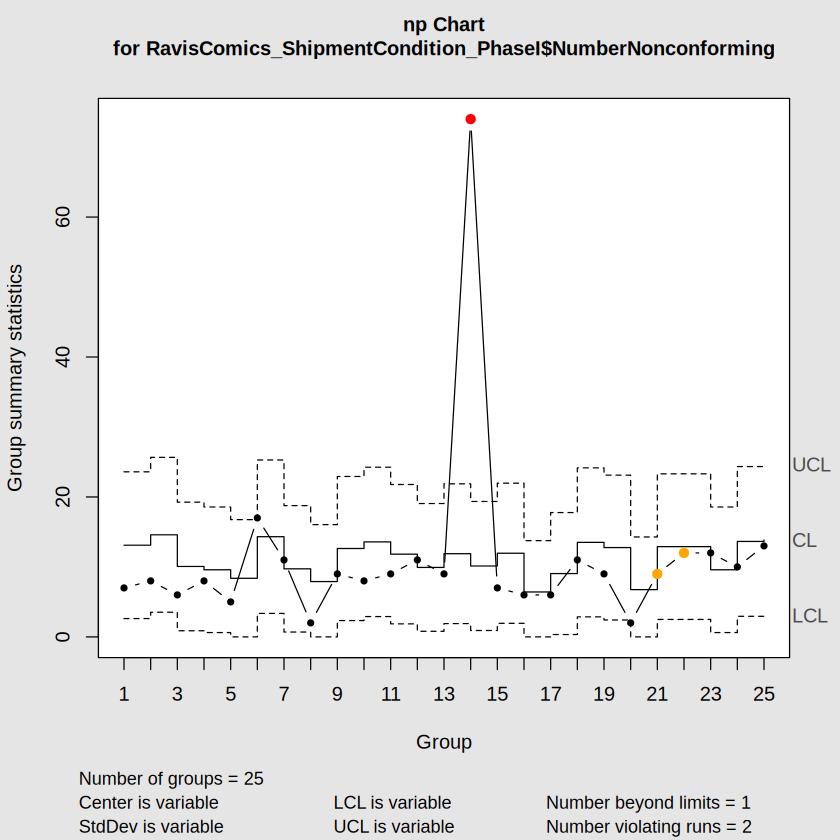

In [7]:
## Q5 Code ##

RavisComics_np_chart <- qcc(RavisComics_ShipmentCondition_PhaseI$'NumberNonconforming',
                         type="np",
                         sizes=RavisComics_ShipmentCondition_PhaseI$'TotalComics',
                         plot=TRUE)

When running the NP chart, we still found that Week 14 violated the upper control limt. This is the same conclusion we had when running the P chart analysis. Will omit the ooc points and will rerun the NP Chart.

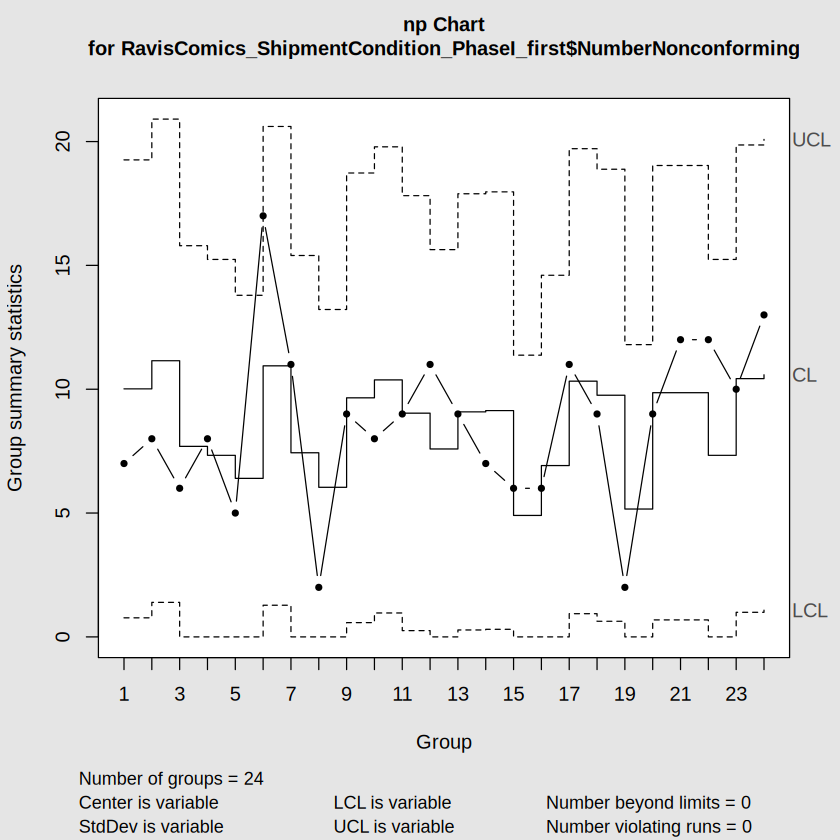

In [8]:
ooc_np_points <- RavisComics_np_chart$violations$beyond.limits

RavisComics_ShipmentCondition_NP_PhaseI_first <- RavisComics_ShipmentCondition_PhaseI[-ooc_np_points,]

RavisComics_ShipmentCondition_PhaseI_NP_firstchart <- qcc(RavisComics_ShipmentCondition_PhaseI_first$NumberNonconforming,
                       type="np",
                       sizes=RavisComics_ShipmentCondition_PhaseI_first$TotalComics,
                       plot=TRUE)

### Q6: Using your finalized Phase I estimate of $\bar{p}$, report the center line and control limits you will carry forward into Phase II.

In [9]:
## Q6 Code ##

pbar <- sum(RavisComics_ShipmentCondition_PhaseI_first$NumberNonconforming) /
        sum(RavisComics_ShipmentCondition_PhaseI_first$TotalComics)
sigp <- sqrt(pbar*(1-pbar))

ucl_i <- pbar + 3*sigp/sqrt(RavisComics_ShipmentCondition_PhaseI_first$TotalComics)
lcl_i <- pmax(0, pbar - 3*sigp/sqrt(RavisComics_ShipmentCondition_PhaseI_first$TotalComics))

cat("p-bar:", pbar, "\n")
cat("sqrt(pbar(1-pbar)):", sigp, "\n")
cat("UCL range:", min(ucl_i), "to", max(ucl_i), "\n")
cat("LCL range:", min(lcl_i), "to", max(lcl_i), "\n")

p-bar: 0.05162095 
sqrt(pbar(1-pbar)): 0.2212605 
UCL range: 0.09678557 to 0.1197235 
LCL range: 0 to 0.00645633 


## Improve

### Q7: After seeing your Phase I results, Ravi calls the distributor, who agrees to add cardboard stiffeners to every shipping box going forward. Briefly explain why it would not be appropriate to use your *original* (uncleaned) Phase I control limits, rather than the finalized limits from Q6, to judge whether this packaging fix actually worked.

The original limits were computed with Week 14 included. Including this outlier would inflate the limit values as well as the Center line.Phase I limits are intended to characterize a process operating under common-cause variation only. This is why we should use the *cleaned* version to cross examine Phase 2

## Control

### Q8: Read the Phase II Shipment Condition data into R. Using your finalized Phase I center line and control limits from Q6, construct the Phase II $p$ chart. Do any weeks plot outside the control limits? Does this support the conclusion that the packaging fix worked?

Week,TotalComics,NumberNonconforming
<dbl>,<dbl>,<dbl>
1,134,6
2,188,1
3,91,5
4,143,1
5,161,10
6,133,4


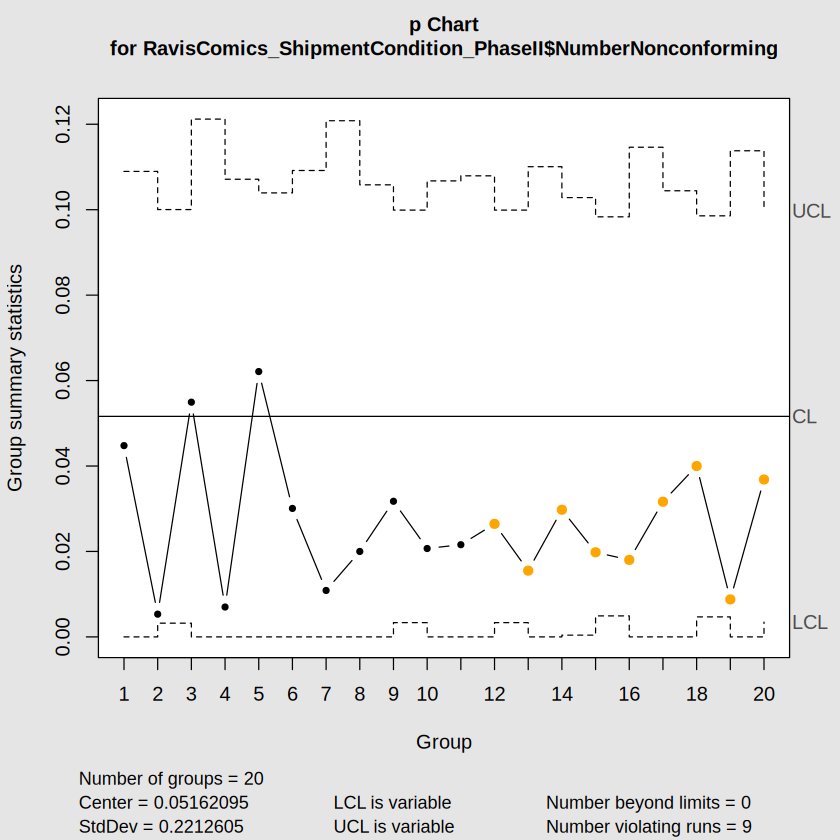

In [10]:
## Q8 Code ##
RavisComics_ShipmentCondition_PhaseII <- read_xlsx("RavisComics_ShipmentCondition_PhaseII.xlsx")
RavisComics_ShipmentCondition_PhaseII |>
  head()

#ucl_i is phaseI upper control limit
#lcl_i is phaseI lower control limit
#pbar is phaseI pbar
#standard deviation is sigp from PhaseI

Ravi_chartp2 <- qcc(RavisComics_ShipmentCondition_PhaseII$NumberNonconforming,
                   type="p",
                   sizes=RavisComics_ShipmentCondition_PhaseII$TotalComics,
                   center=pbar,
                   std=sigp,
                   plot=TRUE)


While none of the Phase II points plot out of control, there's still a visible pattern suggesting the proportion nonconforming may have shifted downward. Of course, a lower fraction nonconforming is a good process improvement, but one worth confirming statistically rather than just eyeballing.

In [11]:
## Let's test it using a two-sample Z test! ##

x1 <- sum(RavisComics_ShipmentCondition_PhaseI_first$NumberNonconforming)
x2 <- sum(RavisComics_ShipmentCondition_PhaseII$NumberNonconforming)
n1 <- sum(RavisComics_ShipmentCondition_PhaseI_first$TotalComics)
n2 <- sum(RavisComics_ShipmentCondition_PhaseII$TotalComics)

prop.test(c(x1,x2), c(n1,n2), alternative = "two.sided",
          correct = FALSE)


	2-sample test for equality of proportions without continuity correction

data:  c(x1, x2) out of c(n1, n2)
X-squared = 26.33, df = 1, p-value = 2.877e-07
alternative hypothesis: two.sided
95 percent confidence interval:
 0.01555768 0.03348726
sample estimates:
    prop 1     prop 2 
0.05162095 0.02709848 


Since the P values are very small, we have significant evidence that the Phase II proportion is genuinely different from our Phase I proportion. The process really has shifted

# Q9: Repeat Q8 using an $np$ chart instead. Is your conclusion consistent with Q8?

Week,TotalComics,NumberNonconforming,CL,UCL,LCL,OOC
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
1,134,6,6.917207,14.60103,0.0000000,FALSE
2,188,1,9.704738,18.80605,0.6034232,FALSE
3,91,5,4.697506,11.02958,0.0000000,FALSE
4,143,1,7.381796,15.31947,0.0000000,FALSE
5,161,10,8.310973,16.73342,0.0000000,FALSE
6,133,4,6.865586,14.52069,0.0000000,FALSE


Week,TotalComics,NumberNonconforming,CL,UCL,LCL,OOC
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>


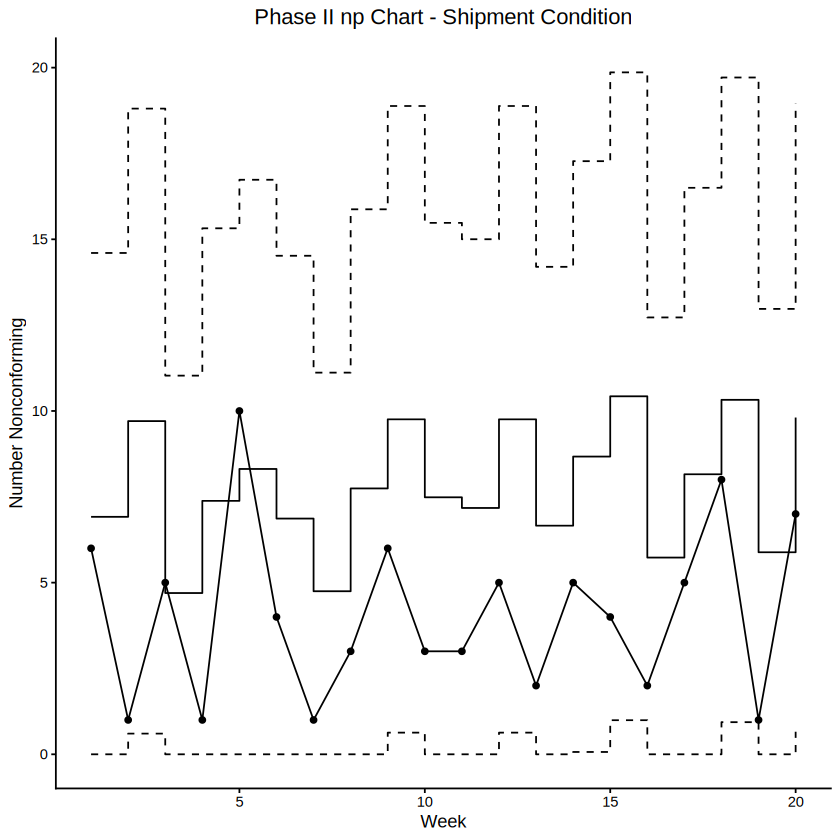

In [16]:
## Q9 Code ##

## np Chart with manually calculated limits ##
## Sample size varies weekly, so CL, UCL and LCL are computed at each n_i
## using the finalized Phase I estimate pbar = 0.05162095

np2 <- RavisComics_ShipmentCondition_PhaseII |>
  mutate(CL  = TotalComics*pbar,
         UCL = CL + 3*sqrt(TotalComics*pbar*(1-pbar)),
         LCL = pmax(0, CL - 3*sqrt(TotalComics*pbar*(1-pbar))),
         OOC = NumberNonconforming > UCL | NumberNonconforming < LCL)

np2 |>
  head()

## Any weeks beyond the limits? ##

np2 |>
  filter(OOC)


ggplot(np2, aes(x = Week)) +
  geom_line(aes(y = NumberNonconforming)) +
  geom_point(aes(y = NumberNonconforming, color = OOC)) +
  geom_step(aes(y = CL)) +
  geom_step(aes(y = UCL), linetype = "dashed") +
  geom_step(aes(y = LCL), linetype = "dashed") +
  scale_color_manual(values = c("FALSE" = "black", "TRUE" = "red")) +
  labs(x = "Week",
       y = "Number Nonconforming",
       title = "Phase II np Chart - Shipment Condition") +
  theme_classic() +
  theme(plot.title = element_text(hjust = 0.50),
        legend.position = "none")

Yes it is consistent with Question 8's results. None of the Phase II points plot out of control (outside the UCL and LCL limits).

### Q10: Read the New-Release Defect Counts data (Dataset B) into R. Construct a $c$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

Week,BoxesInspected,NumberOfDefects
<dbl>,<dbl>,<dbl>
1,5,14
2,5,8
3,5,9
4,5,8
5,5,11
6,5,10


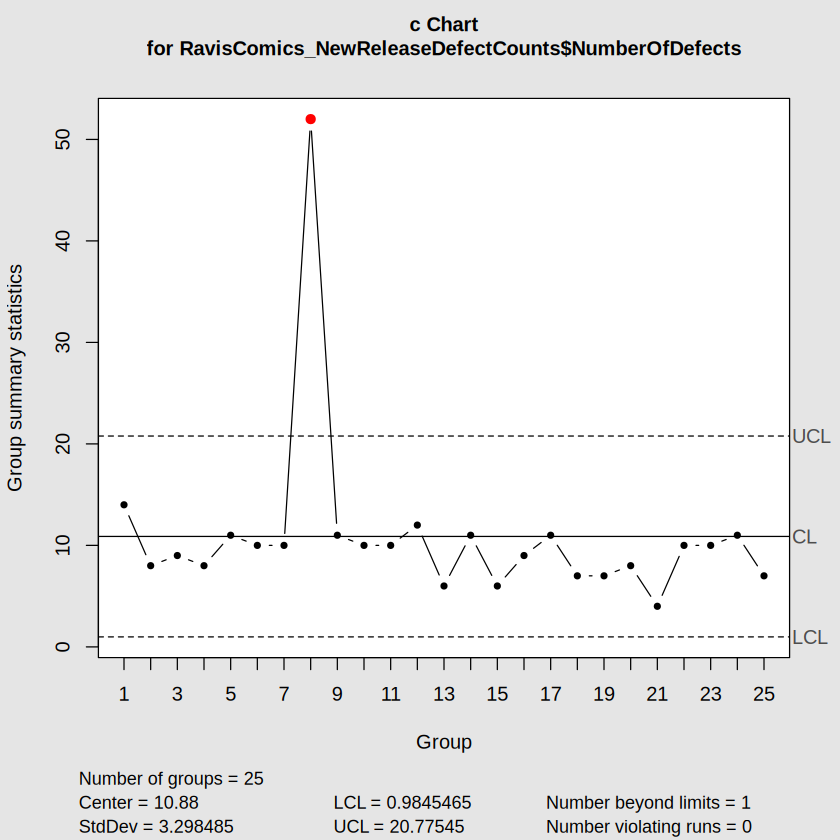

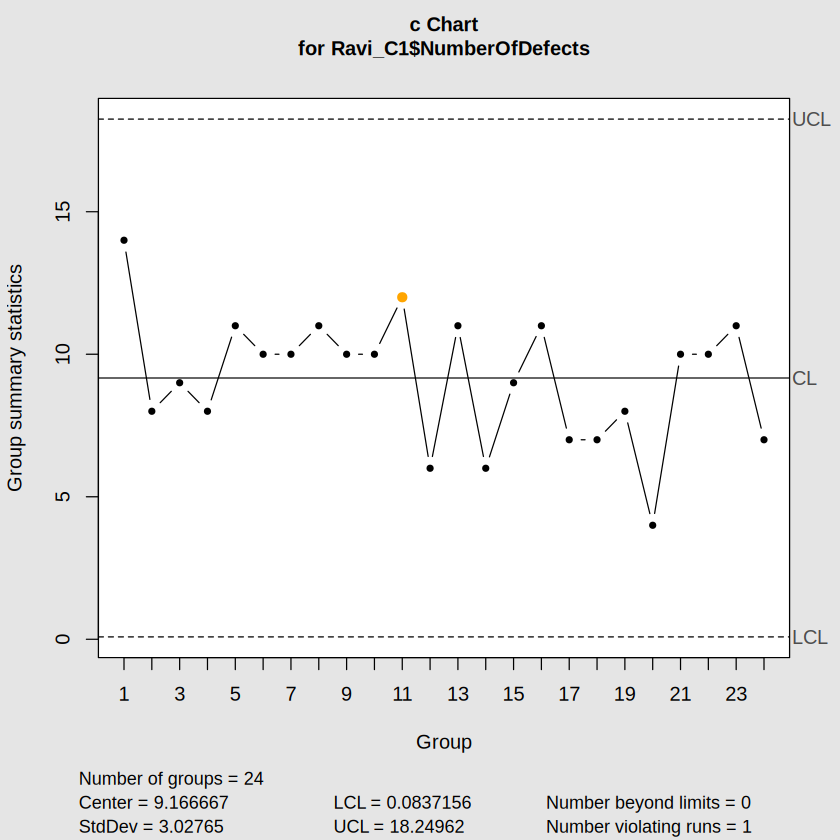

In [13]:
## Q10 Code ##
RavisComics_NewReleaseDefectCounts <- read_xlsx("RavisComics_NewReleaseDefectCounts.xlsx")
RavisComics_NewReleaseDefectCounts |>
  head()

Ravi_chart_C <- qcc(RavisComics_NewReleaseDefectCounts$NumberOfDefects,
                          type="c",plot=T)

## One OOC Point was Detected ##

ooc_points <- Ravi_chart_C$violations$beyond.limits

Ravi_C1 <- RavisComics_NewReleaseDefectCounts[-ooc_points,]

Ravi_C_chart1 <- qcc(Ravi_C1$NumberOfDefects,
                           type="c",plot=T)

When we first ran the analysis, there was 1 ooc point at week 8. Contextually, this could have been explained by damage incurred during the transit from the distributer to the store. We omitted that point and re-ran the QCC. The cleaned version has no points beyond the UCL and LCL. There is 1 violating run. Since there are no numbers beyond the limits, this shows statistical control.

### Q11: Using your finalized $c$ chart, report $\bar{c}$ and the control limits. In 1-2 sentences, explain what this chart tells Ravi that the Q4-Q9 pass/fail analysis could not.

The finalized $c$ chart gives $\bar{c} = 9.17$ defects per weekly 5-box sample, with $UCL = 18.25$ and $LCL = 0.08$.

This chart tells Ravi how severely the comics are damaged, which the pass/fail analysis could not: the $p$ and $np$ charts treat a comic with one minor scratch and a comic with six separate scratches identically, counting both as a single nonconforming unit, whereas the $c$ chart counts every individual defect and therefore captures the depth of the damage rather than only its incidence.

### Q12: Read the Back-Issue Defect Counts data (Dataset C) into R. Construct a $u$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

Week,BoxesInspected,NumberOfDefects
<dbl>,<dbl>,<dbl>
1,8,9
2,10,11
3,5,0
4,3,2
5,4,2
6,5,9


Week,BoxesInspected,NumberOfDefects
<dbl>,<dbl>,<dbl>
17,6,34


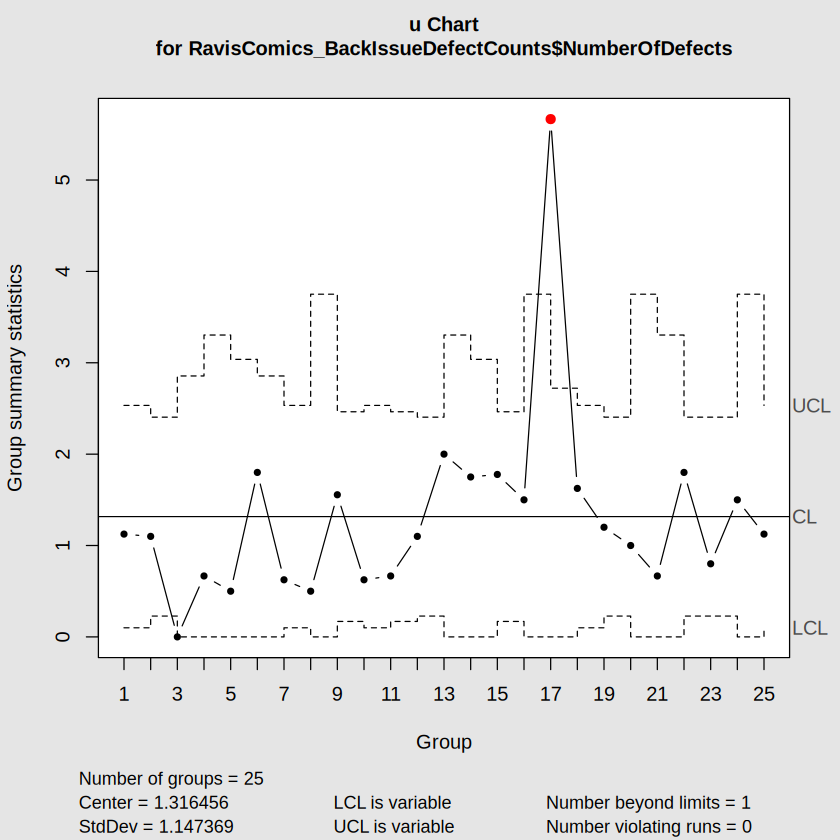

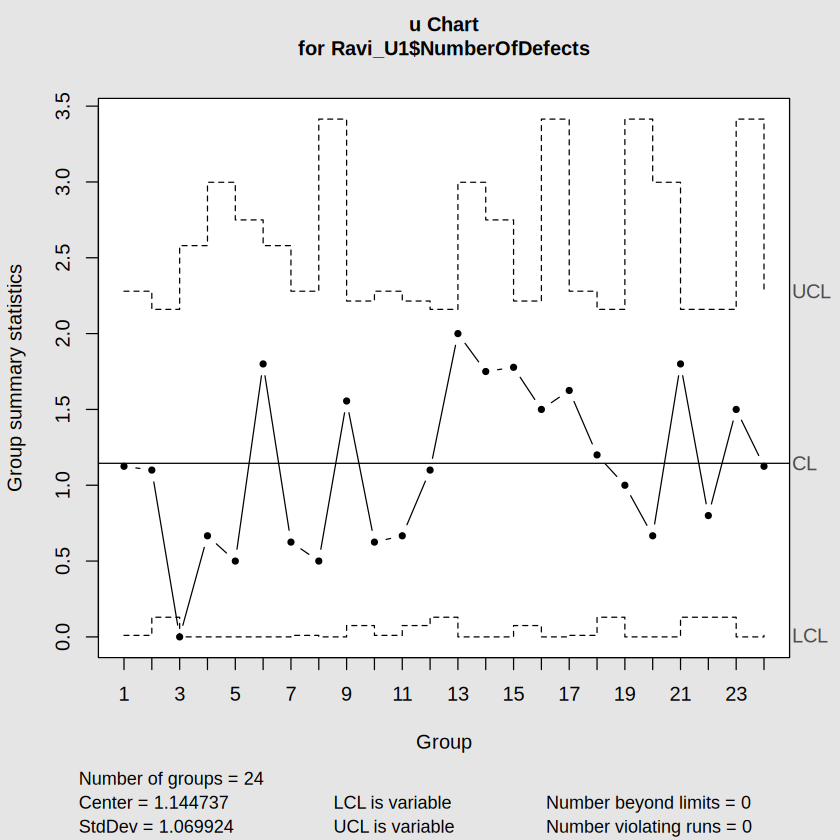

In [14]:
## Q12 Code ##
RavisComics_BackIssueDefectCounts <- read_xlsx("RavisComics_BackIssueDefectCounts.xlsx")
RavisComics_BackIssueDefectCounts |>
  head()

RavisComics_BackIssueDefectCounts_chart <- qcc(RavisComics_BackIssueDefectCounts$NumberOfDefects,
                     type="u",sizes=RavisComics_BackIssueDefectCounts$BoxesInspected)

## One OOC Point was Detected ##

ooc_points_u <- RavisComics_BackIssueDefectCounts_chart$violations$beyond.limits

## Identify the week before removing it ##

RavisComics_BackIssueDefectCounts[ooc_points_u, ]

Ravi_U1 <- RavisComics_BackIssueDefectCounts[-ooc_points_u,]

Ravi_U_chart1 <- qcc(Ravi_U1$NumberOfDefects,
                     type = "u",
                     sizes = Ravi_U1$BoxesInspected,
                     plot = T)

When we first ran the analysis, there was 1 ooc point at week 17. Contextually, Because the back-issue inventory has already been received, unboxed, and shelved, transit damage from the distributor cannot explain this point. This could be due to a drop of a box or mismangement from the employees. We omitted that point and re-ran the QCC. The cleaned version has no points beyond the UCL and LCL. Since there are no numbers beyond the limits, this shows statistical control.

### Q13: Suppose you tried to build a $c$ chart on the Back-Issue Defect Counts data instead of a $u$ chart. Why would this not be an appropriate choice, given how the data were collected?

A $c$ chart would not be appropriate because it assumes a constant inspection unit from sample to sample. A $c$ chart plots the raw defect count against a single fixed center line and fixed control limits.

This means the chart would take into account of both the severity of damage with the volume of inspection. The $u$ chart resolves this by dividing each count by its own number of inspection units, $u_i = x_i/n_i$, producing a comparable rate each week.

### Q14: Provide an overview of your results that Ravi can use the next time he calls the distributor's account representative. Citing specific evidence from your $p$/$np$ analysis **and** your $c$/$u$ analysis, which parts of the damage problem look like they're the distributor's responsibility, and which parts (if any) look more like an internal, in-shop handling issue?

P/NP Analysis: The cardboard stiffeners the distributors provided helped lower the percentage of damaged comic books. the proportion of comics arriving damaged fell from 5.2% to 2.7%. A two-sample proportion test confirms the drop is statistically significant (p < 0.001).

C Analysis: the defect-count analysis shows those books typically carry multiple scratches, averaging 9.2 defects per weekly 5-box sample. Week 14 on the condition chart and Week 8 on the defect-count chart showed the OOC weeks. Based on this, I do reccoemnd that the dsitributor provide extra protections on their shipments.

U Analysis: The back-issue chart shows that those comics were already received and shelved before the damage was counted, and Week 17 flagged out of control there. This shows that there needs to be some in store training/handling care Ravi would need to provide to his team.